# RPY Comparison: Native (mag-fused) vs Quaternion-derived (no mag)
Reads `rpy_data.csv` produced by `rpy_logger.py` and plots both RPY sources side by side.

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('rpy_data.csv')

# convert timestamp to seconds from start
df['t'] = (df['timestamp_us'] - df['timestamp_us'].iloc[0]) / 1e6

print(f'Loaded {len(df)} samples, duration {df["t"].iloc[-1]:.1f}s')
df.head()

Loaded 593 samples, duration 59.9s


,timestamp_us,native_r,native_p,native_y,quat_r,quat_p,quat_y,t
0,1774990769347786,-0.0608,0.0646,0.0004,-0.0608,0.0647,-0.002,0.000000
1,1774990769448827,-0.0606,0.0646,0.0004,-0.0608,0.0648,-0.002,0.101041
2,1774990769548620,-0.0606,0.0646,0.0004,-0.0608,0.0648,-0.002,0.200834
3,1774990769650103,-0.0606,0.0646,0.0004,-0.0606,0.0648,-0.002,0.302317
4,1774990769751550,-0.0606,0.0646,0.0004,-0.0606,0.0648,-0.002,0.403764


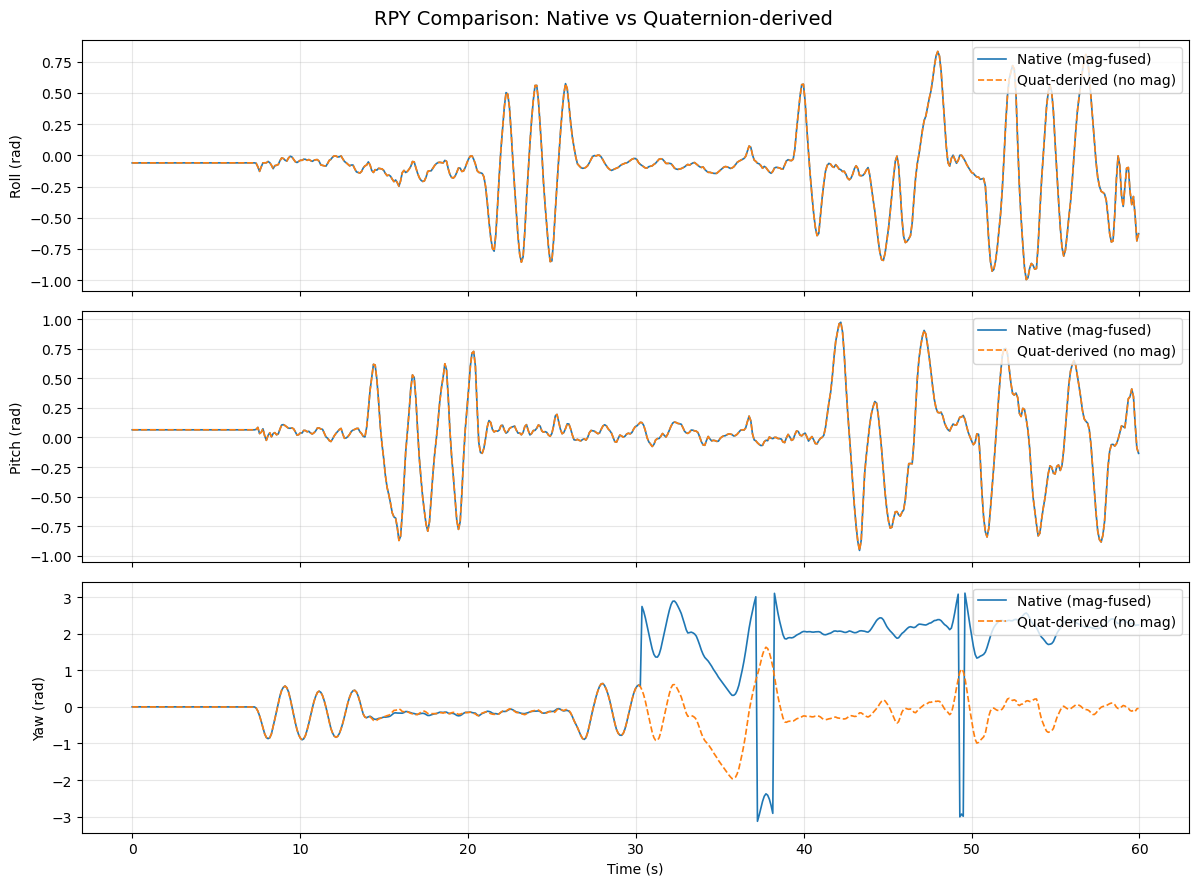

Saved rpy_compare.png


In [30]:
labels = ['Roll', 'Pitch', 'Yaw']
native_cols  = ['native_r', 'native_p', 'native_y']
quat_cols    = ['quat_r',   'quat_p',   'quat_y']

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, label, nc, qc in zip(axes, labels, native_cols, quat_cols):
    ax.plot(df['t'], df[nc], label='Native (mag-fused)',  linewidth=1.2)
    ax.plot(df['t'], df[qc], label='Quat-derived (no mag)', linewidth=1.2, linestyle='--')
    ax.set_ylabel(f'{label} (rad)')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Time (s)')
fig.suptitle('RPY Comparison: Native vs Quaternion-derived', fontsize=14)
plt.tight_layout()
plt.savefig('rpy_compare.png', dpi=150)
plt.show()
print('Saved rpy_compare.png')